# Phase 2: Advanced Medication & Regimen Complexity Analytics
This notebook explores advanced medication change metrics, polypharmacy stratification, and high-risk glycemic transitions to enhance the predictive performance of the PharmaLens clinical pipeline.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Add project root to path to import src modules
ROOT = Path().resolve().parent if "notebooks" in str(Path().resolve()) else Path().resolve()
sys.path.append(str(ROOT))

from src.data_loader import load_export_table, load_kpis
from src.medication_features import compute_regimen_complexity, flag_high_risk_transitions

print("Root directory:", ROOT)
print("Dependencies loaded successfully!")

Root directory: D:\learning\Epsilon\Data Science\PDF lec\Decodelab\readmission-project
Dependencies loaded successfully!


In [2]:
# Load KPI metrics and available mimic or patient data exports
try:
    kpis = load_kpis()
    print("KPIs loaded successfully. Baseline ROC-AUC:", kpis.get("holdout_roc_auc"))
    
    # Load mimic top drugs or subgroup exports as a proxy for medication analysis
    df_drugs = load_export_table("mimic_top_drugs.csv")
    print("MIMIC top drugs shape:", df_drugs.shape)
    display(df_drugs.head())
except Exception as e:
    print("Note: Running in standalone or mock mode:", e)

KPIs loaded successfully. Baseline ROC-AUC: 0.64
MIMIC top drugs shape: (15, 3)


,drug,orders,admissions
0,Acetaminophen,344,176
1,Heparin,287,173
2,Docusate Sodium,250,155
3,Senna,217,148
4,Magnesium Sulfate,402,138


## Applying Regimen Complexity Transformations
We apply our modular functions from `src/medication_features.py` to evaluate regimen volatility, polypharmacy indices, and high-risk transitions.

In [3]:
# Create a sample dataframe simulating clinical encounter medication data for experimentation
sample_data = pd.DataFrame({
    "num_medications": [2, 6, 4, 8, 1],
    "any_dose_change": [False, True, True, False, True],
    "drugs_changed_cap": [0, 3, 1, 0, 2],
    "insulin": [True, False, True, False, False],
    "metformin": [False, True, False, True, False]
})

# Apply transformations
transformed_df = compute_regimen_complexity(sample_data)
transformed_df = flag_high_risk_transitions(transformed_df)

display(transformed_df)

,num_medications,any_dose_change,drugs_changed_cap,insulin,metformin,regimen_volatility_score,is_high_polypharmacy,regimen_stability_score,high_risk_glycemic_transition
0,2,False,0,True,False,0.0,False,1.00,False
1,6,True,3,False,True,3.0,True,0.50,True
2,4,True,1,True,False,1.0,False,0.75,True
3,8,False,0,False,True,0.0,True,1.00,False
4,1,True,2,False,False,2.0,False,0.00,False


## Visualizing Regimen Stability vs. Volatility
Exploring the distribution of stability scores across simulated or cohort data.

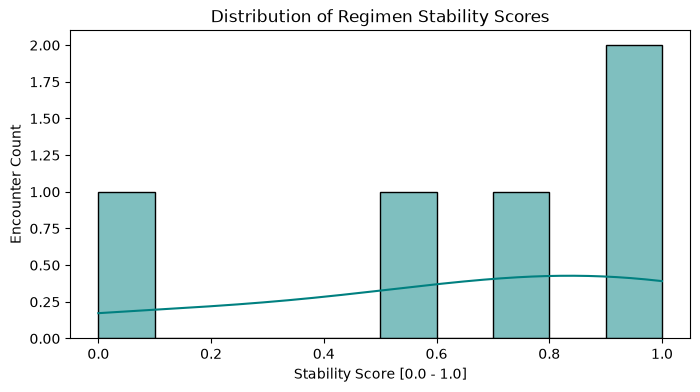

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(transformed_df["regimen_stability_score"], bins=10, kde=True, color="teal")
plt.title("Distribution of Regimen Stability Scores")
plt.xlabel("Stability Score [0.0 - 1.0]")
plt.ylabel("Encounter Count")
plt.show()